# PC3 · Modelo de difusión para generar rostros de anime

**Script de entrenamiento.** DDPM (Ho et al., 2020) entrenado desde cero con el *Anime Face Dataset* (Kaggle, 63 565 rostros), tomando como base el Colab de clase *Diffusion Models* (CelebA, TensorFlow).

| | Colab de clase | Este trabajo |
|---|---|---|
| Dataset | CelebA, 202 599 rostros reales | Anime Face Dataset, 63 565 rostros |
| Condición | ninguna | **época** (2000-2004 … 2015-2019) tomada del año del archivo, con guía sin clasificador |
| Framework | TensorFlow / Keras | PyTorch, precisión mixta bf16 (GPU local de 8 GB) |
| U-Net | 19,4 M parámetros, MaxPooling y Conv2DTranspose | 18,2 M parámetros, conv. con stride y Upsample + Conv, dropout |
| Pérdida | Huber | MSE (L_simple del paper) |
| Data augmentation | función vacía | volteo horizontal aleatorio |
| Pesos | los del último paso | promedio EMA de los pesos, warmup del LR y recorte de gradiente |
| Muestreo | DDPM, 1000 pasos | DDPM 1000 pasos y DDIM 50 pasos (unas 20 veces más rápido) |

Se mantienen del Colab: T = 1000, β lineal de 1e-4 a 0,02, imágenes de 64×64 escaladas a [-1, 1], embedding sinusoidal del tiempo, bloques residuales con GroupNorm y atención.

In [1]:
import os, time, datetime, json
import numpy as np
import torch
import matplotlib.pyplot as plt
from modelo import UNet, Difusion, EMA, EPOCAS, epoca_de

dev = "cuda"
torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")

PyTorch 2.14.1+cu126
GPU: NVIDIA GeForce RTX 4060 (8.6 GB)


In [2]:
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv

name, driver_version, memory.total [MiB]
NVIDIA GeForce RTX 4060, 610.88, 8188 MiB


## 1. Hiperparámetros

In [3]:
TAM = 64
BATCH = 64
EPOCAS_ENT = 50
LR = 2e-4
WARMUP = 1000
T = 1000
BETA_INI, BETA_FIN = 1e-4, 0.02
P_NULA = 0.1
EMA_DECAY = 0.9995
CANALES = 64

## 2. Datos

`preparar_datos.py` redimensiona las 63 565 imágenes a 64×64 y guarda el año de cada una. La época se obtiene del año.

In [4]:
d = np.load("datos/anime64.npz")
X = torch.from_numpy(d["imgs"]).permute(0, 3, 1, 2).contiguous().pin_memory()
años = d["años"].astype(np.int64)
E = torch.from_numpy(epoca_de(años))
print("Imágenes:", tuple(X.shape))
for k, nombre in enumerate(EPOCAS):
    print(f"  {nombre}: {(E == k).sum().item()}")

Imágenes: (63565, 3, 64, 64)
  2000-2004: 10400
  2005-2009: 17882
  2010-2014: 20639
  2015-2019: 14644


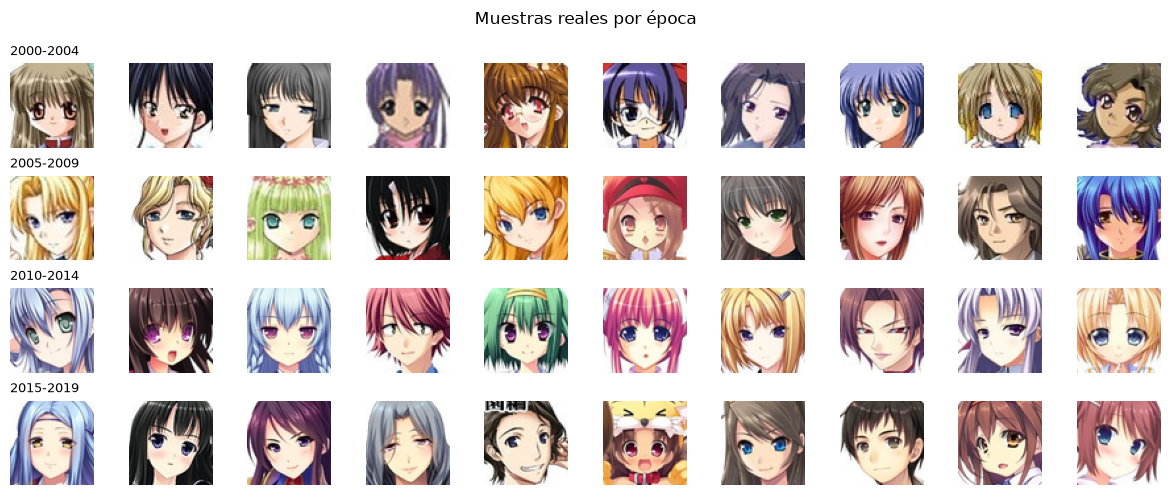

In [5]:
fig, ax = plt.subplots(4, 10, figsize=(12, 5))
rng = np.random.default_rng(0)
for k, nombre in enumerate(EPOCAS):
    idx = rng.choice(np.where(E.numpy() == k)[0], 10, replace=False)
    for j, i in enumerate(idx):
        ax[k, j].imshow(d["imgs"][i]); ax[k, j].axis("off")
    ax[k, 0].set_title(nombre, fontsize=9, loc="left")
plt.suptitle("Muestras reales por época"); plt.tight_layout(); plt.show()

**Preprocesamiento** (igual para todas las imágenes): escalar de [0, 255] a [-1, 1], como en los Colabs de clase.

**Data augmentation** (aleatorio y solo en entrenamiento): volteo horizontal con probabilidad 0,5.

## 3. Proceso directo: la forma cerrada sobre una imagen real

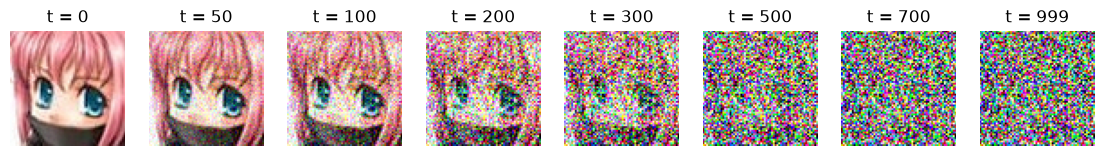

In [6]:
dif = Difusion(T, BETA_INI, BETA_FIN, dev)
x0 = (X[100:101].float().to(dev) / 127.5 - 1)
torch.manual_seed(0)
eps = torch.randn_like(x0)
ts = [0, 50, 100, 200, 300, 500, 700, 999]
fig, ax = plt.subplots(1, len(ts), figsize=(14, 2.2))
for a, t in zip(ax, ts):
    xt = dif.ruidosa(x0, torch.tensor([t], device=dev), eps)
    a.imshow(((xt[0].permute(1, 2, 0) + 1) / 2).clamp(0, 1).cpu()); a.axis("off"); a.set_title(f"t = {t}")
plt.show()

## 4. Modelo

In [7]:
red = UNet(ch=CANALES, attn_res=(8,)).to(dev)
ema = EMA(red, EMA_DECAY)
opt = torch.optim.AdamW(red.parameters(), lr=LR, fused=True)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / WARMUP))
print(f"Parámetros: {sum(p.numel() for p in red.parameters()) / 1e6:.1f} M")

Parámetros: 18.2 M


## 5. Entrenamiento

Cada paso: tomar un lote, un *t* al azar y ruido; armar $x_t$ con la forma cerrada; la U-Net predice el ruido y se minimiza $\lVert \epsilon - \epsilon_\theta(x_t, t, \text{época}) \rVert^2$. El 10 % de las veces la época se reemplaza por "sin condición" para poder usar guía sin clasificador.

Al final de cada época se guardan los pesos y una grilla de muestras (EMA, DDIM 50 pasos, mismo ruido fijo, una fila por época).

In [8]:
os.makedirs("pesos", exist_ok=True)
os.makedirs("muestras", exist_ok=True)
inicio, log, curva = 0, [], []
if os.path.exists("pesos/checkpoint.pt"):
    ck = torch.load("pesos/checkpoint.pt", weights_only=False)
    red.load_state_dict(ck["red"]); ema.red.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
    opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    inicio, log, curva = ck["epoca"], ck["log"], ck["curva"]
    print(f"Reanudando desde la época {inicio}")

z_fijo = torch.randn(32, 3, TAM, TAM, generator=torch.Generator().manual_seed(0)).to(dev)
e_fijo = torch.arange(4).repeat_interleave(8).to(dev)
pasos = len(X) // BATCH
t_inicio = time.time() - sum(r["segundos"] for r in log)
print("Inicio:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"), f"| {pasos} pasos por época")

for ep in range(inicio, EPOCAS_ENT):
    t0 = time.time()
    red.train()
    perm = torch.randperm(len(X))
    suma, parcial = torch.zeros((), device=dev), torch.zeros((), device=dev)
    for k in range(pasos):
        i = perm[k * BATCH:(k + 1) * BATCH]
        x = X[i].to(dev, non_blocking=True).float() / 127.5 - 1
        x = torch.where(torch.rand(len(i), 1, 1, 1, device=dev) < 0.5, x.flip(3), x)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            l = dif.perdida(red, x, E[i].to(dev), P_NULA)
        opt.zero_grad(set_to_none=True)
        l.backward()
        torch.nn.utils.clip_grad_norm_(red.parameters(), 1.0)
        opt.step(); sched.step(); ema.actualizar(red)
        suma += l.detach(); parcial += l.detach()
        if (k + 1) % 100 == 0:
            curva.append(parcial.item() / 100); parcial.zero_()
    perdida = suma.item() / pasos

    with torch.autocast("cuda", dtype=torch.bfloat16):
        m, _ = dif.ddim(ema.red, z_fijo, e_fijo, n=50, guia=2.0)
    m = ((m.float() + 1) / 2).cpu().permute(0, 2, 3, 1).numpy()
    grilla = np.vstack([np.hstack(list(m[r * 8:(r + 1) * 8])) for r in range(4)])
    plt.imsave(f"muestras/epoca_{ep + 1:02d}.png", grilla)

    seg = time.time() - t0
    log.append({"epoca": ep + 1, "perdida": perdida, "segundos": seg})
    torch.save({"red": red.state_dict(), "ema": ema.red.state_dict(), "ema_n": ema.n, "opt": opt.state_dict(),
                "sched": sched.state_dict(), "epoca": ep + 1, "log": log, "curva": curva}, "pesos/checkpoint.pt")
    torch.save(ema.red.state_dict(), "pesos/pesos_ema.pt")
    print(f"Época {ep + 1:2d}/{EPOCAS_ENT} | pérdida {perdida:.4f} | {seg / 60:.1f} min | total {(time.time() - t_inicio) / 60:.0f} min", flush=True)

print("Fin:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

Inicio: 2026-11-08 18:18:49 | 993 pasos por época


Época  1/50 | pérdida 0.1717 | 7.2 min | total 7 min


Época  2/50 | pérdida 0.0418 | 5.9 min | total 13 min


Época  3/50 | pérdida 0.0354 | 5.9 min | total 19 min


Época  4/50 | pérdida 0.0337 | 5.6 min | total 25 min


Época  5/50 | pérdida 0.0328 | 5.7 min | total 30 min


... (42 outputs left out)

Época 48/50 | pérdida 0.0272 | 5.7 min | total 272 min


Época 49/50 | pérdida 0.0269 | 5.7 min | total 277 min


Época 50/50 | pérdida 0.0269 | 5.6 min | total 283 min


Fin: 2026-11-08 23:01:42


## 6. Evidencias del entrenamiento

In [9]:
total = sum(r["segundos"] for r in log)
print(f"Épocas: {len(log)} | pasos: {len(log) * pasos} | tiempo total: {total / 3600:.2f} h")
for f in ["pesos/pesos_ema.pt", "pesos/checkpoint.pt"]:
    print(f"{f}: {os.path.getsize(f) / 1e6:.1f} MB")
json.dump(log, open("pesos/log_entrenamiento.json", "w"), indent=1)

Épocas: 50 | pasos: 49650 | tiempo total: 4.71 h
pesos/pesos_ema.pt: 72.9 MB
pesos/checkpoint.pt: 291.8 MB


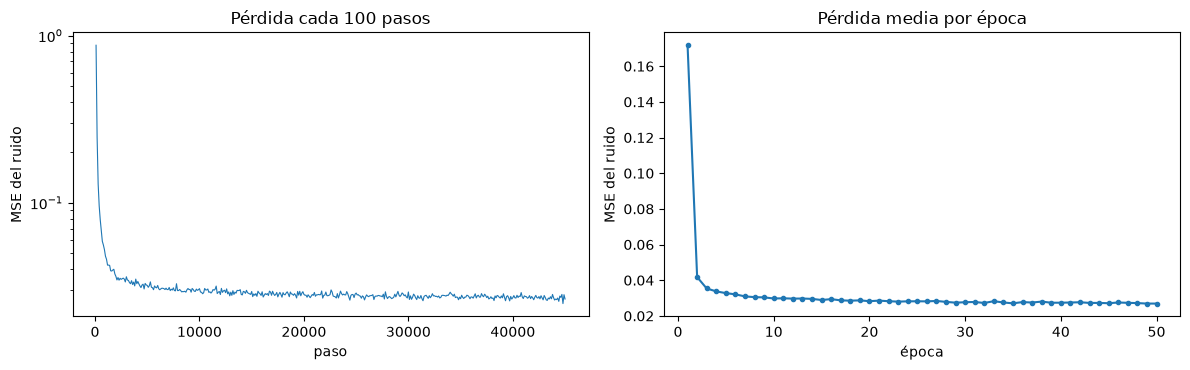

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(1, len(curva) + 1) * 100, curva, lw=0.8)
ax[0].set_xlabel("paso"); ax[0].set_ylabel("MSE del ruido"); ax[0].set_yscale("log"); ax[0].set_title("Pérdida cada 100 pasos")
ax[1].plot([r["epoca"] for r in log], [r["perdida"] for r in log], "o-", ms=3)
ax[1].set_xlabel("época"); ax[1].set_ylabel("MSE del ruido"); ax[1].set_title("Pérdida media por época")
plt.tight_layout(); plt.savefig("muestras/curva_perdida.png", dpi=120); plt.show()

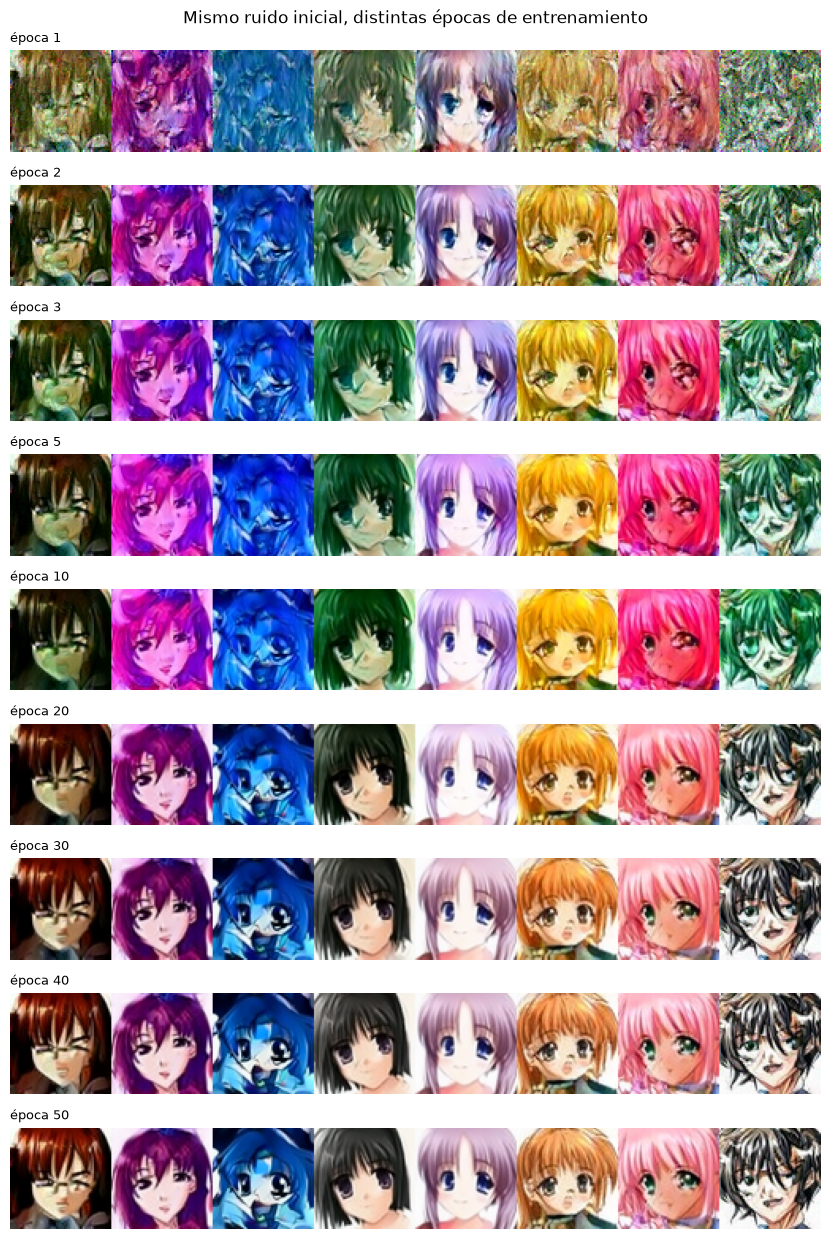

GIF: 50 cuadros


In [11]:
import imageio.v2 as imageio
eps_ver = [e for e in [1, 2, 3, 5, 10, 20, 30, 40, 50] if e <= len(log)]
fig, ax = plt.subplots(len(eps_ver), 1, figsize=(10, 1.4 * len(eps_ver)))
for a, e in zip(np.atleast_1d(ax), eps_ver):
    a.imshow(plt.imread(f"muestras/epoca_{e:02d}.png")[:64]); a.axis("off"); a.set_title(f"época {e}", fontsize=9, loc="left")
plt.suptitle("Mismo ruido inicial, distintas épocas de entrenamiento"); plt.tight_layout(); plt.show()

cuadros = [(plt.imread(f"muestras/epoca_{r['epoca']:02d}.png")[..., :3] * 255).astype(np.uint8) for r in log]
imageio.mimsave("muestras/evolucion_entrenamiento.gif", cuadros, duration=0.4, loop=0)
print("GIF:", len(cuadros), "cuadros")